In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import xgboost as xgb
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuración de gráficos para paper
plt.style.use('default')
sns.set_theme(style="ticks", context="paper", font_scale=1.2)

# Definición de la arquitectura PyTorch (necesaria para cargar los pesos)
class ImprovedMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout_rate=0.3):
        super(ImprovedMLP, self).__init__()
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim), nn.BatchNorm1d(hidden_dim),
                nn.LeakyReLU(0.1), nn.Dropout(dropout_rate)
            ])
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, 1))
        self.network = nn.Sequential(*layers)
    def forward(self, x):
        return self.network(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cpu


/home/cocdrilo/miniconda3/envs/imblearn/lib/python3.10/site-packages/xgboost/core.py:377: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(


In [2]:
# 1. Definir Rutas
data_path = Path('../data/raw/NeoPepBase.csv')
models_dir = Path('../models/production/hybrid_ensemble')

# 2. Cargar Dataset y Replicar Split Exacto
print("Cargando datos y replicando partición de Test...")
df = pd.read_csv(data_path)

features_to_drop = ['immunogenicity', 'mut_is_binding_pos', 'bestWTMatchType_I', 
                    'DAI_MixMHC_mbp', 'mutant_rank']
X_df = df.select_dtypes(include=['float64', 'int64']).drop(columns=features_to_drop, errors='ignore')

X = X_df.values
y = df['immunogenicity'].values

# Replicamos el split exacto que usaste en el entrenamiento (random_state=42)
X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(
    X, y, df, test_size=0.20, random_state=42, stratify=y
)

# 3. Cargar Modelos Entrenados
print("Cargando modelos y generando predicciones...")
scaler = joblib.load(models_dir / 'scaler.pkl')
X_test_scaled = scaler.transform(X_test)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)

input_dim = X_test.shape[1]
# OJO: Pon aquí las dimensiones exactas de tu modelo (ej. [180, 77, 251] o [128, 64])
pytorch_model = ImprovedMLP(input_dim, hidden_dims=[180, 77, 251], dropout_rate=0.3).to(device)
pytorch_model.load_state_dict(torch.load(models_dir / 'pytorch_final.pth', map_location=device, weights_only=True))
pytorch_model.eval()

xgb_model = xgb.XGBClassifier()
xgb_model.load_model(models_dir / 'xgboost_final.json')

# 4. Calcular Probabilidades (Asumiendo pesos 50/50, cámbialos si es necesario)
with torch.no_grad():
    p_prob = torch.sigmoid(pytorch_model(X_test_tensor)).cpu().numpy().flatten()
x_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

w1, w2 = 0.5, 0.5 
df_test['ensemble_prob'] = (w1 * p_prob) + (w2 * x_prob)
df_test['true_label'] = y_test

print("✓ Predicciones generadas con éxito.")

Cargando datos y replicando partición de Test...
Cargando modelos y generando predicciones...
✓ Predicciones generadas con éxito.


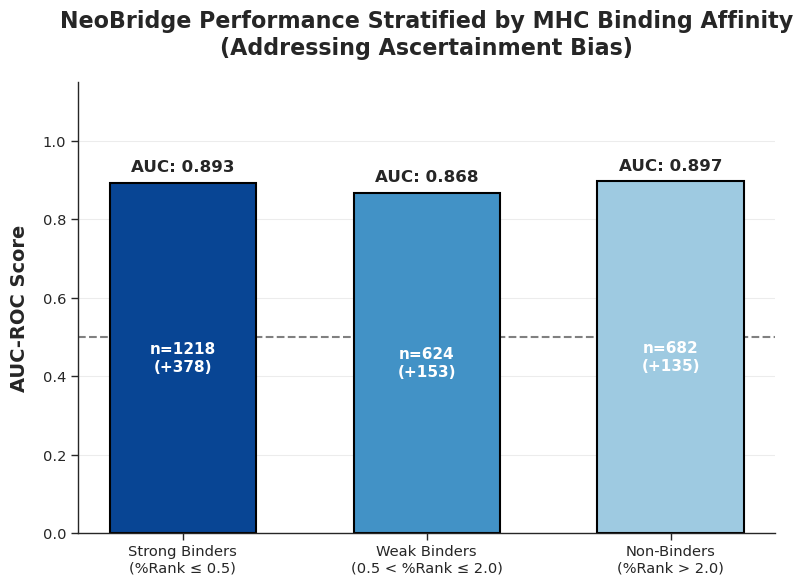

✓ Análisis completado. Figura guardada en: ../results/figures/Post_HOC_analysis/Figure_Ascertainment_Bias_Affinity_Stratification.png

RESUMEN DE RESULTADOS PARA EL PAPER:
                         Category      AUC  N_total
    Strong Binders\n(%Rank ≤ 0.5) 0.892763     1218
Weak Binders\n(0.5 < %Rank ≤ 2.0) 0.868081      624
       Non-Binders\n(%Rank > 2.0) 0.897217      682


In [3]:
# 1. Estratificar por Categorías Clínicas de Afinidad
bins = [-np.inf, 0.5, 2.0, np.inf]
labels = ['Strong Binders\n(%Rank ≤ 0.5)', 'Weak Binders\n(0.5 < %Rank ≤ 2.0)', 'Non-Binders\n(%Rank > 2.0)']
df_test['Affinity_Category'] = pd.cut(df_test['mutant_rank'], bins=bins, labels=labels)

# 2. Calcular AUC y N para cada categoría
results = []
for category in labels:
    subset = df_test[df_test['Affinity_Category'] == category]
    n_total = len(subset)
    n_pos = subset['true_label'].sum()
    
    # Solo calculamos AUC si hay al menos una clase positiva y una negativa
    if n_pos > 0 and n_pos < n_total:
        auc = roc_auc_score(subset['true_label'], subset['ensemble_prob'])
    else:
        auc = np.nan
        
    results.append({
        'Category': category,
        'AUC': auc,
        'N_total': n_total,
        'N_pos': n_pos
    })

df_results = pd.DataFrame(results)

# 3. Dibujar la Gráfica de Barras (Calidad Paper)
fig, ax = plt.subplots(figsize=(8, 6))

# Paleta de colores científicos (Azul fuerte para Strong Binders)
colors = ['#084594', '#4292c6', '#9ecae1']

bars = ax.bar(df_results['Category'], df_results['AUC'], color=colors, 
              edgecolor='black', linewidth=1.5, width=0.6)

# Añadir el texto del AUC y la (N) encima de cada barra
for bar, row in zip(bars, df_results.itertuples()):
    if not np.isnan(row.AUC):
        yval = bar.get_height()
        # Texto del AUC
        ax.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"AUC: {row.AUC:.3f}", 
                ha='center', va='bottom', fontsize=12, fontweight='bold')
        # Texto de la N (Péptidos en esa categoría)
        ax.text(bar.get_x() + bar.get_width()/2, yval / 2, f"n={row.N_total}\n(+{row.N_pos})", 
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

# Estética de los ejes
ax.set_ylim(0, 1.15)
ax.set_ylabel('AUC-ROC Score', fontsize=14, fontweight='bold', labelpad=10)
ax.set_title('NeoBridge Performance Stratified by MHC Binding Affinity\n(Addressing Ascertainment Bias)', 
             fontsize=16, fontweight='bold', pad=20)

# Línea base aleatoria (AUC = 0.5)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1.5, zorder=0)

ax.grid(axis='y', linestyle='-', alpha=0.15, color='gray')
sns.despine()
plt.tight_layout()

# Guardar figura
save_path = '../results/figures/Post_HOC_analysis/Figure_Ascertainment_Bias_Affinity_Stratification.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Análisis completado. Figura guardada en: {save_path}")
print("\nRESUMEN DE RESULTADOS PARA EL PAPER:")
print(df_results[['Category', 'AUC', 'N_total']].to_string(index=False))

Brier Score del Ensemble: 0.1251


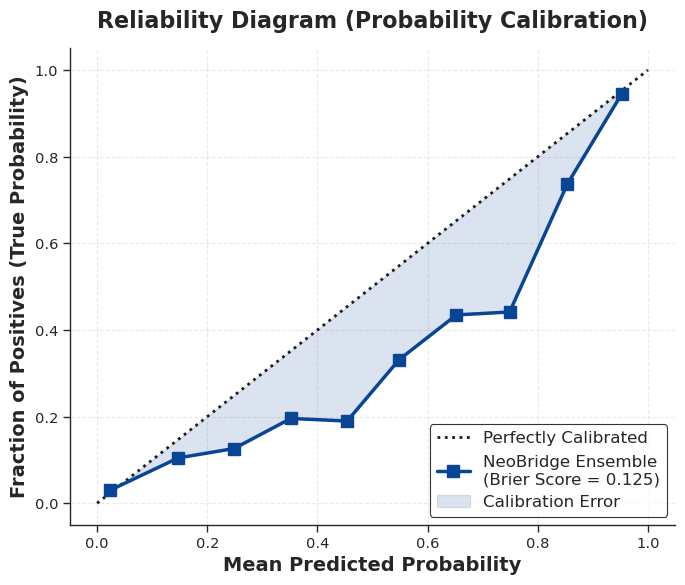

✓ Diagrama de calibración guardado en: ../results/figures/Post_HOC_analysis/Figure_Probability_Calibration.png


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import numpy as np

# 1. Preparar los datos (Asumiendo que ya tienes y_test y df_test['ensemble_prob'])
y_true = df_test['true_label'].values
y_prob = df_test['ensemble_prob'].values

# 2. Calcular Brier Score (Cuanto más cerca de 0, mejor. Un modelo aleatorio da 0.25)
brier_score = brier_score_loss(y_true, y_prob)
print(f"Brier Score del Ensemble: {brier_score:.4f}")

# 3. Calcular los puntos de la curva de calibración
# n_bins=10 agrupa las probabilidades en rangos de 10% (0-10%, 10-20%, etc.)
fraction_of_positives, mean_predicted_value = calibration_curve(y_true, y_prob, n_bins=10, strategy='uniform')

# 4. Configurar la Figura Científica
plt.style.use('default')
sns.set_theme(style="ticks", context="paper", font_scale=1.2)
fig, ax = plt.subplots(figsize=(7, 6))

# Línea ideal (Calibración perfecta)
ax.plot([0, 1], [0, 1], "k:", label="Perfectly Calibrated", linewidth=2)

# Curva de nuestro modelo (Ensemble)
ax.plot(mean_predicted_value, fraction_of_positives, "s-", color='#084594',
        label=f"NeoBridge Ensemble\n(Brier Score = {brier_score:.3f})", linewidth=2.5, markersize=8)

# Rellenar el área entre la línea ideal y nuestro modelo para visualizar el "Error de Calibración"
ax.fill_between(mean_predicted_value, mean_predicted_value, fraction_of_positives, 
                color='#084594', alpha=0.15, label="Calibration Error")

# Estética
ax.set_ylabel("Fraction of Positives (True Probability)", fontsize=14, fontweight='bold')
ax.set_xlabel("Mean Predicted Probability", fontsize=14, fontweight='bold')
ax.set_title("Reliability Diagram (Probability Calibration)", fontsize=16, fontweight='bold', pad=15)
ax.set_xlim([-0.05, 1.05])
ax.set_ylim([-0.05, 1.05])
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc="lower right", fontsize=12, frameon=True, edgecolor='black')
sns.despine()

plt.tight_layout()

# Guardar
save_path = '../results/figures/Post_HOC_analysis/Figure_Probability_Calibration.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Diagrama de calibración guardado en: {save_path}")